# Using Spark, Stopwords, RegularExpression, Matplotlib for Word Cloud

In [1]:
import matplotlib.pyplot as plt
import re
from wordcloud import WordCloud, STOPWORDS
from pyspark import SparkConf, SparkContext
from pyspark.sql import SparkSession

spark = SparkSession.builder.master('local').getOrCreate()

# Create Spark Context and load text file

In [2]:
sc = spark.sparkContext
text_file = sc.textFile('data/manncomm.txt')
#text_file = sc.textFile('data/santi.txt')

# Word Count, sort by key

In [3]:
words = text_file.flatMap(lambda x: ((v) for v in re.split('\\W',x)))       
wc = words.map(lambda word: (word, 1)).reduceByKey(lambda a, b: a + b).sortBy(lambda x: x[1], ascending=False).collectAsMap()
print(words)

PythonRDD[7] at RDD at PythonRDD.scala:53


In [4]:
print(wc)

{'': 2228, 'the': 1037, 'of': 774, 'and': 333, 'to': 253, 'in': 239, 'a': 157, 'is': 134, 'that': 123, 'by': 108, 'The': 102, 'class': 102, 'with': 97, 'bourgeois': 94, 'bourgeoisie': 90, 'all': 84, 'as': 81, 'its': 76, 'their': 75, 'for': 75, 'it': 70, 'society': 67, 'has': 66, 'proletariat': 62, 'they': 61, 'are': 56, 'this': 55, 'property': 55, 'into': 53, 'more': 51, 'production': 51, 'on': 50, 'conditions': 50, 'In': 48, 'which': 43, 'have': 42, 'not': 42, 'but': 41, 'be': 40, 'labour': 37, 'from': 36, 'social': 36, 'these': 35, 'against': 34, 'at': 34, 'no': 34, 'one': 33, 'modern': 32, 'existence': 32, 'only': 32, 'so': 30, 'It': 29, 'an': 29, 'means': 29, 'political': 27, 'Socialism': 27, 'old': 26, 'development': 26, 'working': 26, 'itself': 25, 'was': 25, 'relations': 25, 'form': 25, 'up': 24, 'therefore': 24, 'industry': 23, 'every': 23, 'But': 23, 'Communists': 22, 'feudal': 22, 'other': 22, 'capital': 22, 'own': 22, 'German': 21, 'whole': 21, 'or': 21, 'classes': 21, 'will

# Get the list of words

In [5]:
wordlist1 = words.collect()
wordlist2 = wc.keys()
print(len(wordlist1),len(wordlist2))

13780 2398


# Remove stopwords, you can also add your own stopwords

In [6]:
stopwords = set(STOPWORDS)
# remove all the digits,and some extra words
new_words = ['ebook', 'gutenberg', 'https', '', '1', '10', '1830', '1846', '1847', '1888', '18th', '2', '3', '4', '5', '6', '7', '8', '9']
#new_words = ['ebook', 'gutenberg', 'https']
stopwords.update(new_words)
print(stopwords)

{'', "i've", '8', 'an', 'when', 'up', "didn't", "we've", '2', 'its', "weren't", 'there', 'was', 'would', 'to', 'him', 'same', 'below', 'in', 'himself', 'ours', '1847', 'because', 'such', 'it', "who's", "i'd", 'if', 'yourselves', 'get', 'but', "shan't", 'otherwise', 'after', '1888', 'he', 'the', "shouldn't", 'these', 'most', '4', '3', 'who', 'against', 'am', 'else', 'between', 'have', 'how', 'what', 'again', 'with', 'few', 'hence', 'before', "wasn't", 'doing', 'while', "why's", 'www', "don't", 'once', "isn't", 'ever', 'you', "they'll", 'over', '10', 'shall', 'gutenberg', 'her', 'out', "she'll", 'of', 'did', 'further', '1', 'they', "i'm", 'own', 'can', 'until', 'cannot', 'down', 'too', 'http', "she's", 'should', 'where', 'off', "can't", "i'll", "doesn't", 'has', 'myself', "how's", 'nor', 'above', 'no', 'by', 'be', 'their', "he'll", 'whom', 'also', 'then', "there's", "we'll", 'themselves', 'hers', 'my', 'or', 'she', "hasn't", "we'd", 'at', 'for', 'we', "aren't", 'ourselves', 'herself', 'n

# Generate and show word cloud

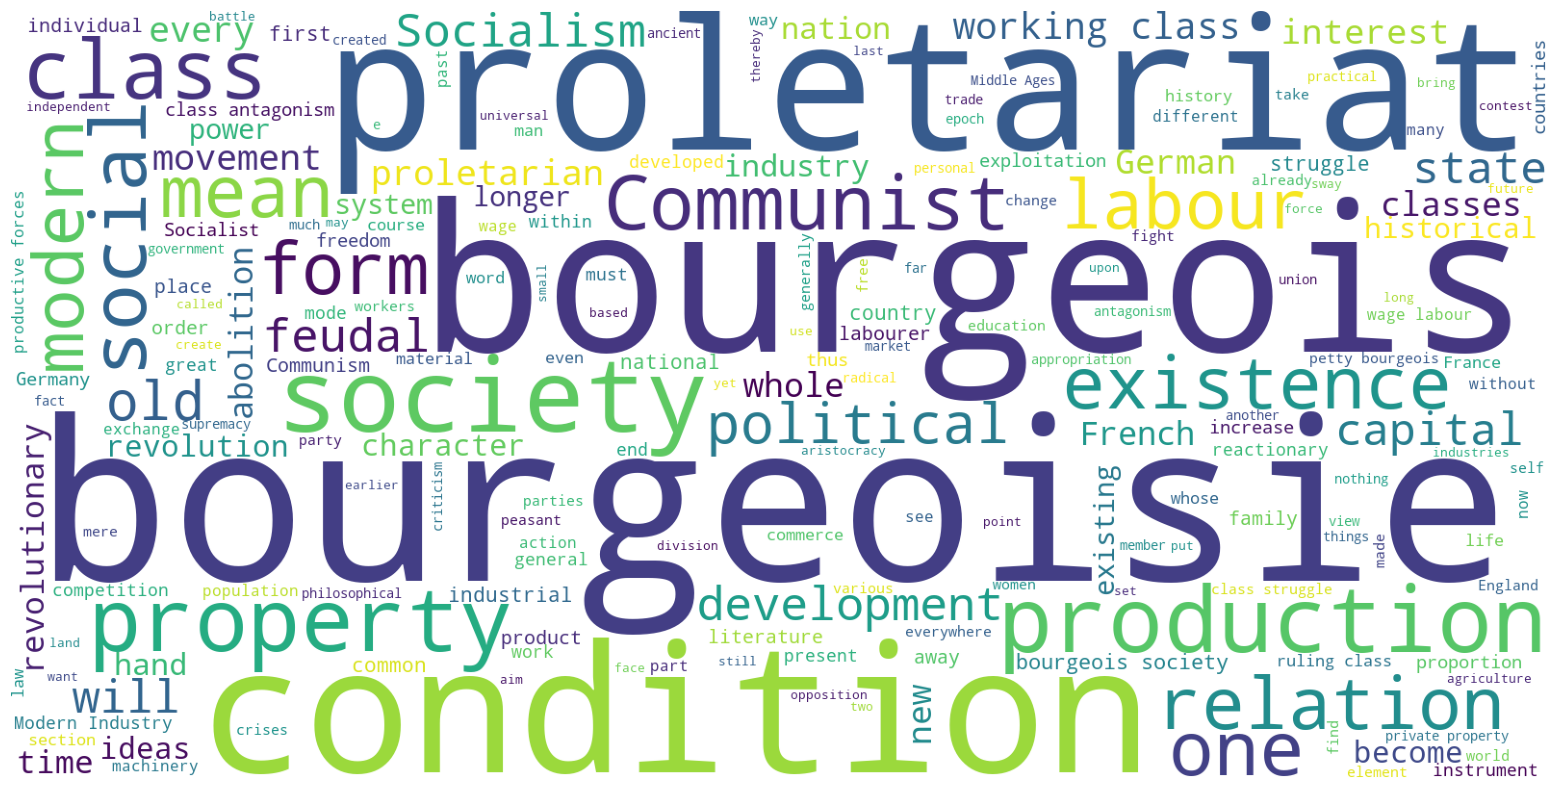

wordcloud.wordcloud.WordCloud

In [7]:
wordcloud1 = WordCloud(stopwords=stopwords, width=1600, height=800, background_color='white')\
            .generate(" ".join(wordlist1))

plt.figure(figsize=(20,10))
plt.imshow(wordcloud1)
plt.axis('off')
plt.show()
type(wordcloud1)

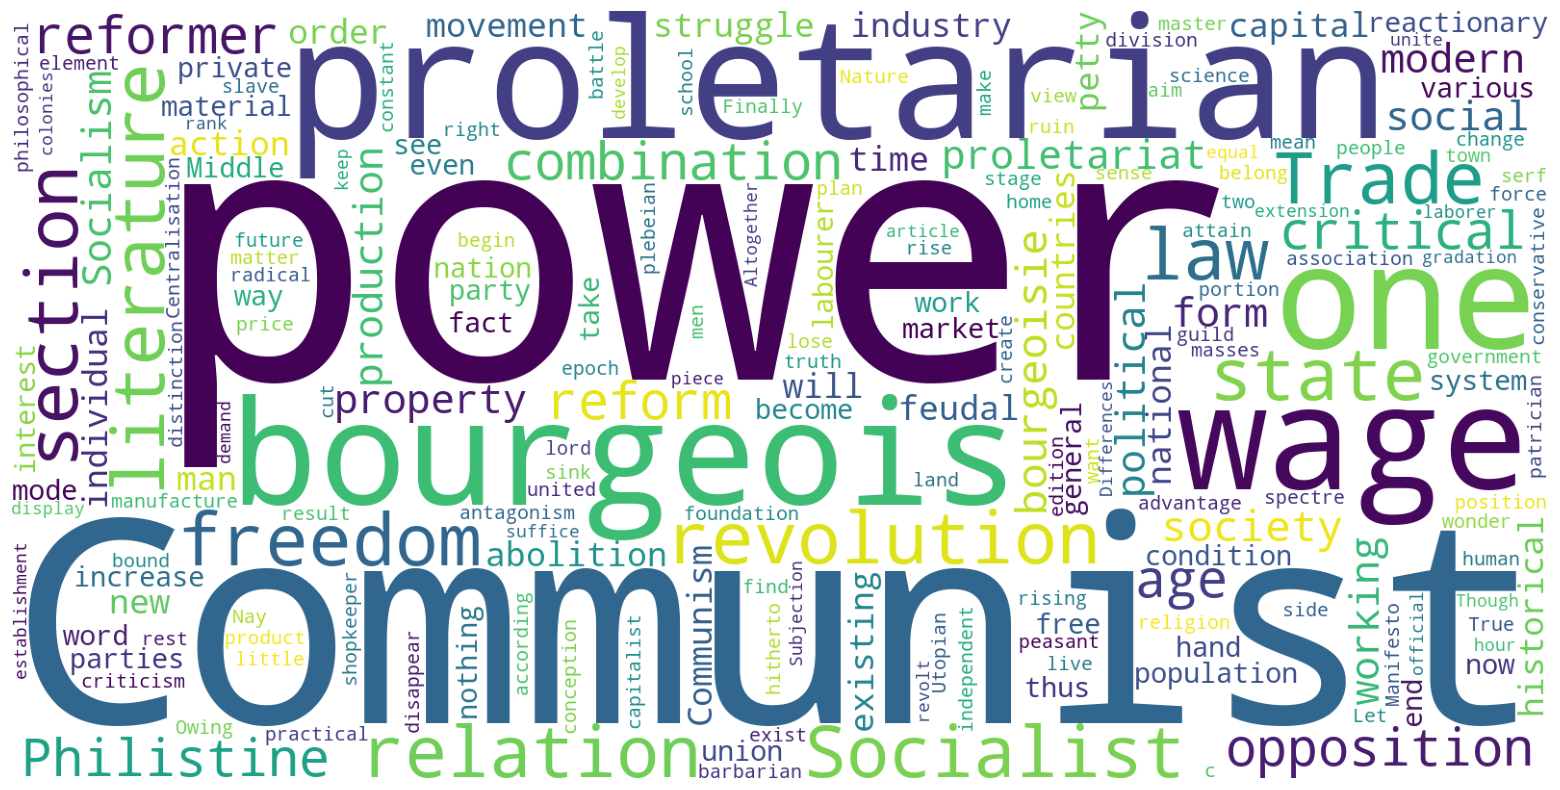

In [8]:
wordcloud2 = WordCloud(stopwords=stopwords, width=1600, height=800, background_color='white')\
            .generate(" ".join(wordlist2))

plt.figure(figsize=(20,10))
plt.imshow(wordcloud2)
plt.axis('off')
plt.show()

# You can also include a picture mask for the result

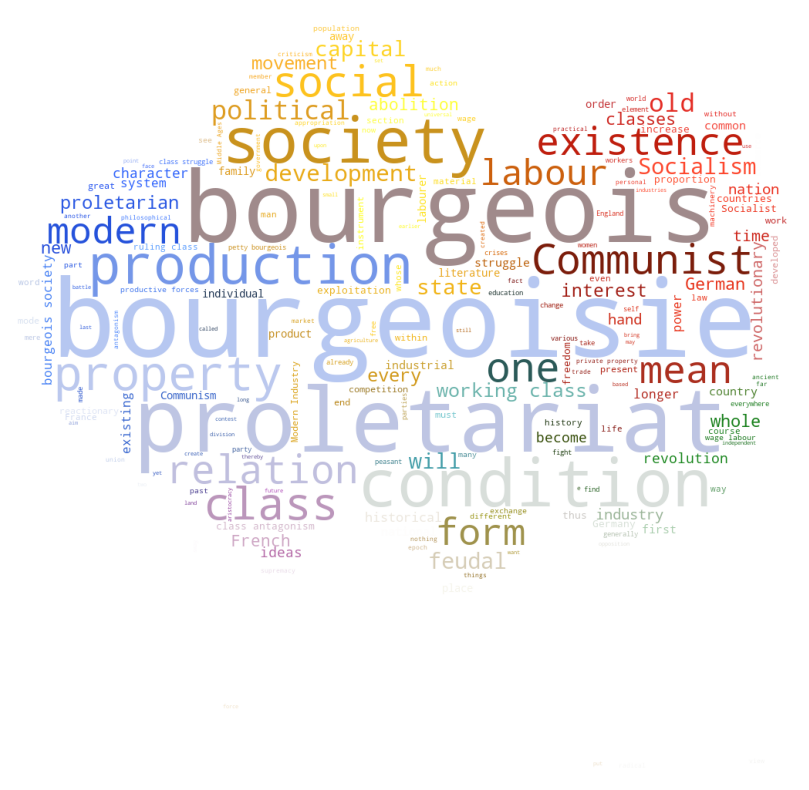

In [9]:
import numpy as np
from PIL import Image
from wordcloud import ImageColorGenerator


background_image = np.array(Image.open('data/balloon.jpg'))

wordcloud3 = WordCloud(stopwords=stopwords, mask=background_image, width=1600, height=800, background_color='white')\
            .generate(" ".join(wordlist1))

plt.figure(figsize=(20,10))

image_colors = ImageColorGenerator(background_image)
plt.imshow(wordcloud3.recolor(color_func=image_colors))

plt.axis('off')
plt.show()

In [10]:
print(type(wordlist1), type(wordlist2))

<class 'list'> <class 'dict_keys'>


In [11]:
spark.stop()